# Video Game Sales — Correlations Across Regions

## Part 1 — Load and Clean Data

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv('video_game_sales.csv')
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [4]:
sales_columns = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

sales_df = df.dropna(subset=sales_columns).reset_index(drop=True)

print(f'Rows before cleaning: {len(df):,}')
print(f'Rows after cleaning:  {len(sales_df):,}')
print(f'Rows removed:         {len(df) - len(sales_df):,}')

Rows before cleaning: 16,598
Rows after cleaning:  16,598
Rows removed:         0


## Part 2 — Correlation Matrix Operations

In [5]:
correlation_matrix = sales_df[sales_columns].corr(method='pearson')
correlation_matrix

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
NA_Sales,1.000000,0.767727,0.449787,0.634737,0.941047
EU_Sales,0.767727,1.000000,0.435584,0.726385,0.902836
JP_Sales,0.449787,0.435584,1.000000,0.290186,0.611816
Other_Sales,0.634737,0.726385,0.290186,1.000000,0.748331
Global_Sales,0.941047,0.902836,0.611816,0.748331,1.000000


### Strongest Dynamic

The correlations with the strongest linear dynamic are NA sales with global sales (0.94) and EU sales with global sales (0.90).

### Weakest Dynamic

The correlations with the weakest linear dynamic are JP sales with all other region sales (0.29) and JP sales with NA sales (~0.45).

## Part 3 — Visualizing the Matrix

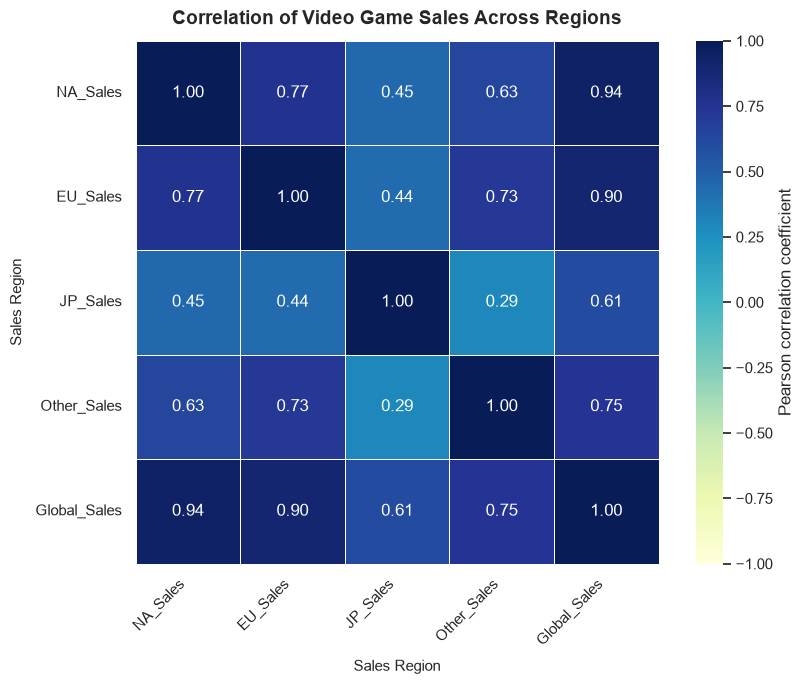

In [6]:
sns.set_theme(style='white')

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Pearson correlation coefficient'},
)

plt.title('Correlation of Video Game Sales Across Regions',
          fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Sales Region', fontsize=11, labelpad=8)
plt.ylabel('Sales Region', fontsize=11, labelpad=8)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Part 4 – Market Interpretation Summary

*What do your calculated coefficients suggest about how a video game's performance in one region relates to its global release performance? Why do you think the specific pairs you identified as the "strongest" and "weakest" behave the way they do? Consider regional gaming cultures, console platform preferences, or population scales in your reasoning.*

My calculated coefficients suggest that there is a strong relationship between sales in North American and sales globally, but especially Europe. This is likely because genres, platforms, and cultures for gaming are most similar across both North America and Europe. Japan sales are an outlier presenting the weakest correlations because of a difference in what kind of games sell and mobile gaming being overwhelmingly popular compared to consoles or PC.